# E3b: ¿conviene normalizar cada noche o suavizar en el tiempo?

**Preguntas.** (1) Qué post-procesado conviene para F y para la HRV. (2) Si la ventaja de juntar RR y EDR sobrevive a la normalización, o era un efecto de escala entre pacientes: el control de E3a mostró que dentro de cada persona el RR solo ya separa bien, y que juntar las señales mejora sobre todo la comparación **entre** personas con un único umbral.

**Diseño (fijado antes de correr).**
- **Candidatas base:**
  - **F:** las 17 del grupo de E3a (potencia cruzada RR–EDR, EDR por área).
  - **HRV:** el grupo de E4 con la misma regla (potencia del RR en VLF o en la banda de apnea, con Lomb).
  - **Controles:** RR solo y EDR solo (log de la potencia en 0,01–0,05 Hz, Welch, 3 min), con la configuración ganadora.
- **Post-procesado (9 combinaciones):** normalización por noche (ninguna; línea de base = restar el percentil 10 de la noche; z-score de la noche) × suavizado (sin, mediana de 3 min, mediana de 5 min). Se aplica sobre todos los minutos de cada noche y después se evalúa sobre los mismos minutos de E3a. El orden no importa: la mediana conmuta con una transformación creciente dentro de la noche.
- **Regla (la de E3a):** AUC con todos los minutos y bootstrap por sujeto; grupo = no inferiores a la mejor con δ = 0,02; dentro del grupo, acierto por registro; si siguen empatadas, la más simple (normalización ninguna < línea de base < z; suavizado sin < 3 < 5; después la complejidad de E3a). Se elige por separado en F, en HRV y en cada control.
- **¿El EDR aporta después de normalizar?** Se compara la F final con el RR solo con su mejor post-procesado. Si el RR solo es no inferior (límite inferior de la diferencia ≥ −0,02), la ventaja de juntar las señales era un efecto de escala entre pacientes.
- **Validación cruzada:** los mismos 5 grupos de sujetos; se repite la elección de E3b y se mide afuera. Referencia: la F de E3a sin post-procesado.
- **Vista previa de H2 (descriptiva):** F final contra HRV final, cada una con su mejor post-procesado.

In [1]:
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)
from src.config import RESULTS_DIR, SPLIT_CSV
from src.features.build import record_minute_table
from src.features.variants import coupling_variants, hrv_variants, postprocess_variants
from src.stats.compare import compare_variants, cross_validate_selection, select_variant, subject_folds

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
CACHE = RESULTS_DIR / "e3"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
GANADORA = pd.read_json(CACHE / "seleccion_e3a.json", typ="series")["acoplamiento"]
GRUPO_F = list(pd.read_csv(CACHE / "grupo_e3a.csv").variante)
print(f"F de E3a: {GANADORA} | grupo de F: {len(GRUPO_F)} candidatas")

F de E3a: area|180s|welch3|apnea|potencia sola | grupo de F: 17 candidatas


In [2]:
# Tablas completas (todos los minutos de cada noche) y los minutos de evaluación de E3a.
coup = pd.read_parquet(CACHE / "acoplamiento.parquet")
hrv = pd.read_parquet(CACHE / "hrv.parquet")
wide_c, meta_c = coupling_variants(coup)
wide_h, meta_h = hrv_variants(hrv)
info = (coup[(coup.edr == "area") & (coup.window == 512) & (coup.estimator == "welch3")]
        .set_index(["record", "minute"])[["label", "corrected"]])
idx = (wide_c.dropna().index.intersection(wide_h.dropna().index)
       .intersection(info.index[(info.label >= 0) & (info.corrected <= 0.2)]))
y = info.loc[idx, "label"].to_numpy().astype(int)
recs = idx.get_level_values("record").to_numpy()
subj = split.loc[recs, "subject"].to_numpy()

# Grupo de HRV con la misma regla que E3a (no inferioridad 0,02)
sel_h0 = select_variant(wide_h.loc[idx], y, subj, recs, meta_h.complejidad, rule="noninferior")
GRUPO_H = sel_h0["grupo"]
f_base, f_meta = wide_c[GRUPO_F], meta_c.loc[GRUPO_F]
h_base, h_meta = wide_h[GRUPO_H], meta_h.loc[GRUPO_H]
del coup, wide_c
print(f"minutos de evaluación: {len(idx):,} | grupo de HRV: {GRUPO_H}")

minutos de evaluación: 22,123 | grupo de HRV: ['hrv|180s|apnea', 'hrv|180s|vlf', 'hrv|240s|apnea', 'hrv|240s|vlf', 'hrv|300s|apnea', 'hrv|300s|vlf', 'hrv|360s|apnea']


In [3]:
# Controles: RR solo y EDR solo con la configuración ganadora (área, 3 min, Welch 3), todos los minutos.
with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
    tablas = list(ex.map(record_minute_table, DEV, [180] * len(DEV), [{"ap": (0.01, 0.05)}] * len(DEV)))
t = pd.concat(tablas).set_index(["record", "minute"])
lg = lambda v: np.log(np.maximum(v, 1e-12))
c_base = pd.DataFrame({"RR solo": lg(t.px_ap), "EDR solo": lg(t.py_ap)})
c_meta = pd.DataFrame({"complejidad": [(0,), (0,)]}, index=c_base.columns)

familias = {}
for nombre, (w, m) in {"F": (f_base, f_meta), "HRV": (h_base, h_meta),
                       "RR solo": (c_base[["RR solo"]], c_meta.loc[["RR solo"]]),
                       "EDR solo": (c_base[["EDR solo"]], c_meta.loc[["EDR solo"]])}.items():
    pw, pm = postprocess_variants(w, m)
    familias[nombre] = (pw.reindex(idx), pm)
    print(f"{nombre}: {pw.shape[1]} candidatas post-procesadas")

F: 153 candidatas post-procesadas


HRV: 63 candidatas post-procesadas


RR solo: 9 candidatas post-procesadas


EDR solo: 9 candidatas post-procesadas


## Elección en cada familia

In [4]:
sel = {n: select_variant(w, y, subj, recs, m.complejidad, rule="noninferior") for n, (w, m) in familias.items()}
filas = []
for n, s in sel.items():
    m = familias[n][1].loc[s["ganadora"]]
    a = s["auc"].loc[s["ganadora"]]
    filas.append({"familia": n, "base": m.base, "normalización": m.normalizacion, "suavizado (min)": m.suavizado,
                  "AUC": a.auc, "IC 95 %": f"{a.ic_lo:.3f} a {a.ic_hi:.3f}",
                  "acierto por registro (Spearman)": s["acuerdo"].loc[s["ganadora"], "spearman"],
                  "tamaño del grupo": len(s["grupo"])})
final = pd.DataFrame(filas).set_index("familia")
final.round(3)

,base,normalización,suavizado (min),AUC,IC 95 %,acierto por registro (Spearman),tamaño del grupo
familia,,,,,,,
F,area|240s|welch3|apnea|potencia sola,none,1,0.876,0.811 a 0.925,0.813,17
HRV,hrv|180s|vlf,none,1,0.810,0.703 a 0.893,0.422,21
RR solo,RR solo,none,1,0.817,0.714 a 0.897,0.386,3
EDR solo,EDR solo,none,1,0.822,0.738 a 0.886,0.740,3


In [5]:
# Para la base ganadora de cada familia: AUC y acierto por registro en las 9 combinaciones.
def grilla(n):
    w, m = familias[n]
    base = m.loc[sel[n]["ganadora"], "base"]
    cols = m.index[m.base == base]
    from src.stats.compare import agreement_compare
    a = sel[n]["auc"].loc[cols, "auc"]
    g = agreement_compare(sel[n]["signos"][cols] * w[cols], y, recs, subj, n_boot=200)["spearman"]
    out = m.loc[cols, ["normalizacion", "suavizado"]].assign(AUC=a, Spearman=g)
    return out.pivot_table(index="normalizacion", columns="suavizado", values=["AUC", "Spearman"]) \
              .reindex(["none", "baseline", "zscore"])

grillas = {n: grilla(n) for n in familias}
for n, g in grillas.items():
    print(f"\n{n}:")
    print(g.round(3).to_string())


F:
                 AUC               Spearman              
suavizado          1      3      5        1      3      5
normalizacion                                            
none           0.876  0.877  0.879    0.813  0.809  0.809
baseline       0.677  0.675  0.673    0.125  0.141  0.126
zscore         0.732  0.735  0.736    0.664  0.681  0.628

HRV:
                 AUC               Spearman              
suavizado          1      3      5        1      3      5
normalizacion                                            
none           0.810  0.811  0.811    0.422  0.412  0.402
baseline       0.793  0.796  0.798    0.478  0.470  0.471
zscore         0.750  0.754  0.757    0.683  0.647  0.669

RR solo:
                 AUC               Spearman              
suavizado          1      3      5        1      3      5
normalizacion                                            
none           0.817  0.821  0.829    0.386  0.399  0.381
baseline       0.698  0.699  0.705    0.164  0.166  

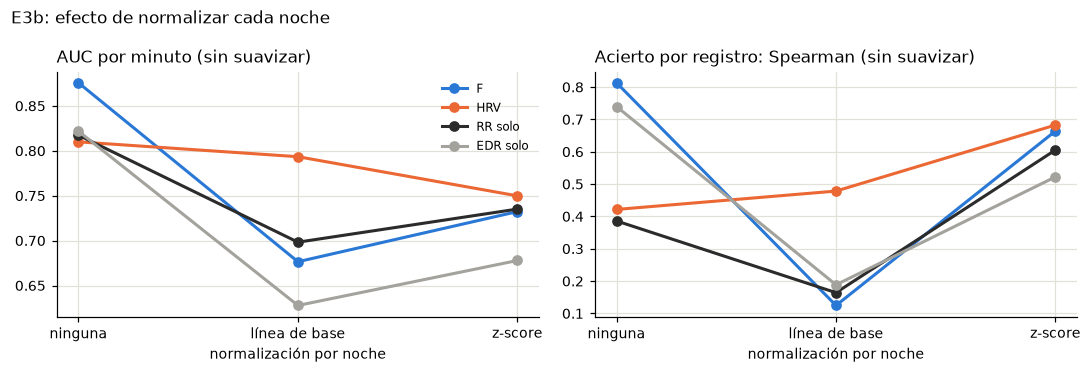

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
etiquetas = {"none": "ninguna", "baseline": "línea de base", "zscore": "z-score"}
colores = {"F": AZUL, "HRV": NARANJA, "RR solo": TINTA, "EDR solo": GRIS}
for n, g in grillas.items():
    for ax, met in zip(axes, ["AUC", "Spearman"]):
        v = g[met][1]                                    # sin suavizar
        ax.plot(range(3), v.to_numpy(), marker="o", color=colores[n], lw=2, label=n)
for ax, t in zip(axes, ["AUC por minuto (sin suavizar)", "Acierto por registro: Spearman (sin suavizar)"]):
    ax.set_xticks(range(3), [etiquetas[k] for k in ["none", "baseline", "zscore"]])
    ax.set_xlabel("normalización por noche"); ax.set_title(t, loc="left")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("E3b: efecto de normalizar cada noche", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "E3b_normalizacion.png")

## ¿El EDR aporta después de normalizar?

In [7]:
par = pd.DataFrame({"F final": sel["F"]["signo"] * familias["F"][0][sel["F"]["ganadora"]],
                    "RR solo final": sel["RR solo"]["signo"] * familias["RR solo"][0][sel["RR solo"]["ganadora"]],
                    "HRV final": sel["HRV"]["signo"] * familias["HRV"][0][sel["HRV"]["ganadora"]]})
r = compare_variants(par[["F final", "RR solo final"]], y, subj, n_boot=2000)
print(r[["auc", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3).to_string())
lo, hi = r.loc["RR solo final", ["dif_lo", "dif_hi"]]
if r.auc.idxmax() != "F final" or lo >= -0.02:
    print("\nRR solo es no inferior a F (margen 0,02): la ventaja de juntar las señales era de escala.")
else:
    print("\nRR solo NO es no inferior a F: la ventaja de F no se puede atribuir a un efecto de escala."
          + (" Además F es mejor (IC por encima de 0)." if hi < 0 else
             " Pero la diferencia tampoco queda confirmada: el IC incluye 0."))

                 auc  ic_lo  ic_hi    dif  dif_lo  dif_hi
F final        0.876  0.811  0.925  0.000   0.000   0.000
RR solo final  0.817  0.714  0.897 -0.058  -0.133   0.011

RR solo NO es no inferior a F: la ventaja de F no se puede atribuir a un efecto de escala. Pero la diferencia tampoco queda confirmada: el IC incluye 0.


### Acierto por registro con IC: ¿qué aporta el EDR para estimar la gravedad de cada noche?

Análisis agregado después de ver la tabla de arriba (descriptivo): el IC por bootstrap de sujetos del Spearman entre la fracción de apnea estimada y la real, para F contra la HRV y para el EDR solo contra el RR solo.

In [8]:
from src.stats.compare import agreement_compare
par_reg = pd.DataFrame({"F final": par["F final"], "HRV final": par["HRV final"],
                        "EDR solo final": sel["EDR solo"]["signo"] * familias["EDR solo"][0][sel["EDR solo"]["ganadora"]],
                        "RR solo final": par["RR solo final"]})
for a, b in (("F final", "HRV final"), ("EDR solo final", "RR solo final")):
    print(agreement_compare(par_reg[[a, b]], y, recs, subj, n_boot=2000).round(3).to_string(), "\n")

           spearman  ic_lo  ic_hi  empata
F final       0.813  0.557  0.935    True
HRV final     0.422 -0.092  0.792   False 



                spearman  ic_lo  ic_hi  empata
EDR solo final     0.740  0.451  0.866    True
RR solo final      0.386 -0.136  0.778    True 



## Validación cruzada y vista previa de H2

In [9]:
tiene_apnea = pd.Series(y, index=subj).groupby(level=0).max().astype(bool)
folds = subject_folds(tiene_apnea, k=5)
ref = f"{GANADORA}|none|k1"
cv = {}
for n in ("F", "HRV"):
    w, m = familias[n]
    cv[n] = cross_validate_selection(w, y, subj, recs, m.complejidad, folds,
                                     reference=ref if n == "F" else None,
                                     n_boot=1000, n_boot_rec=300, rule="noninferior").join(
        m[["normalizacion", "suavizado"]], on="ganadora")
    print(f"\n{n}: AUC al elegir {cv[n]['AUC al elegir'].mean():.3f} | afuera {cv[n]['AUC afuera'].mean():.3f}"
          + (f" | F de E3a sin post-procesar, afuera {cv[n]['referencia afuera'].mean():.3f}" if n == "F" else ""))
    print(cv[n][["normalizacion", "suavizado", "AUC al elegir", "AUC afuera"]].round(3).to_string())


F: AUC al elegir 0.874 | afuera 0.853 | F de E3a sin post-procesar, afuera 0.850
      normalizacion  suavizado  AUC al elegir  AUC afuera
grupo                                                    
1              none          1          0.851       0.946
2              none          1          0.876       0.874
3              none          1          0.898       0.786
4              none          1          0.896       0.693
5              none          1          0.848       0.965



HRV: AUC al elegir 0.811 | afuera 0.807
      normalizacion  suavizado  AUC al elegir  AUC afuera
grupo                                                    
1              none          1          0.809       0.959
2              none          1          0.773       0.912
3              none          1          0.838       0.748
4              none          1          0.848       0.532
5              none          1          0.789       0.884


In [10]:
compare_variants(par[["F final", "HRV final"]], y, subj, n_boot=2000)[["auc", "ic_lo", "ic_hi", "p_mejor", "dif", "dif_lo", "dif_hi"]].round(3)

,auc,ic_lo,ic_hi,p_mejor,dif,dif_lo,dif_hi
F final,0.876,0.811,0.925,0.965,0.000,0.000,0.000
HRV final,0.810,0.703,0.893,0.035,-0.066,-0.142,0.004


In [11]:
pd.Series({n: s["ganadora"] for n, s in sel.items()} |
          {f"signo {n}": s["signo"] for n, s in sel.items()}).to_json(CACHE / "seleccion_e3b.json")
print("guardado:", CACHE / "seleccion_e3b.json")

guardado: C:\Users\afrat\proyectos\Python ITBA\PSIB2026Q2-TPS-Grupo08-Frate Tenca Weizman\results\e3\seleccion_e3b.json


## Decisión

- **Post-procesado: ninguno.** En las cuatro familias la mejor opción es no normalizar ni suavizar.
  - **Normalizar cada noche empeora** el AUC por minuto en todas (F: 0,876 sin normalizar; 0,68 con línea de base; 0,73 con z-score). La línea de base también arruina el acierto por registro (Spearman de F: 0,81 → 0,13). Queda descartada la normalización por registro que proponía el esquema v2.
  - **Suavizar** con una mediana de 3 o 5 minutos cambia el AUC en menos de 0,005, dentro del margen, así que por simplicidad queda sin suavizar.
- **F final: `area|240s|welch3|apnea|potencia sola`**, sin post-procesar: AUC 0,876 (IC 95 % 0,81 a 0,93). Respecto de E3a solo cambia la ventana (4 min en lugar de 3), y las dos rinden prácticamente igual (0,876 y 0,871).
- **HRV final: potencia VLF del RR con Lomb, 3 min**, sin post-procesar: AUC 0,810.
- **Acierto por registro.** Sin normalizar, F estima la fracción de apnea de cada noche mucho mejor que la HRV (Spearman 0,81, IC 0,56 a 0,94, contra 0,42, IC −0,09 a 0,79), y la diferencia es significativa con bootstrap por sujeto. El EDR solo llega a 0,74 y el RR solo a 0,39, aunque esa diferencia no se confirma (el IC incluye 0). Es el aporte más claro del EDR: estimar **cuánta** apnea tiene cada noche, no solo separar minutos dentro de una persona. Se vio en desarrollo, con la misma métrica que se usó para elegir: hay que confirmarlo en test.
- **¿Era un efecto de escala?** Normalizar cada noche no reproduce la ventaja de F: empeora a todas las familias. Con el criterio fijado, el RR solo no es no inferior a F (diferencia −0,058; IC −0,133 a +0,011), así que la ventaja de F no se puede atribuir a un efecto de escala; pero tampoco queda confirmada, porque el IC incluye 0.
- **Validación cruzada:** E3b eligió "sin post-procesar" en los 5 grupos. Afuera, F da 0,853 (igual que sin E3b, 0,850) y la HRV 0,807.
- **Vista previa de H2 (descriptiva):** F 0,876 contra HRV 0,810; diferencia 0,066 (IC −0,004 a +0,142), mejor en el 96,5 % de los remuestreos. Queda cerca del límite y no se confirma con los 19 sujetos de desarrollo: se decide en test.